In [2]:
#Install Libraries
# TextBlob → for sentiment analysis
# Matplotlib → for charts
# TextBlob corpora → extra language data TextBlob needs

pip install textblob matplotlib

   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------------------------------- 625.0/625.0 kB 8.2 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [4]:
!python -m textblob.download_corpora

Finished.


[nltk_data] Downloading package brown to
[nltk_data]     C:\Users\Ifelo\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\brown.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Ifelo\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Ifelo\AppData\Roaming\nltk_data...
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\Ifelo\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping taggers\averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package conll2000 to
[nltk_data]     C:\Users\Ifelo\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\conll2000.zip.
[nltk_data] Downloading package movie_reviews to
[nltk_data]     C:\Users\Ifelo\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\movie_reviews.zip.


In [10]:
!pip install wordcloud

In [5]:
#Import Libraries
import os
from textblob import TextBlob

# Folder containing your email .txt files
EMAIL_FOLDER = "emails"

sentiment_results = []

# Loop through all files in the folder
for filename in os.listdir(EMAIL_FOLDER):
    if filename.endswith(".txt"):
        file_path = os.path.join(EMAIL_FOLDER, filename)

        # Read file content
        with open(file_path, "r", encoding="utf-8") as f:
            text = f.read()

        # Analyse sentiment
        blob = TextBlob(text)
        polarity = blob.sentiment.polarity

        # Store result
        sentiment_results.append((filename, polarity))

# Print results so you can see them
for file, score in sentiment_results:
    print(f"{file}: {score}")


email_1.txt: 0.5
email_2.txt: 0.0
email_3.txt: -0.75


C:\Users\Ifelo\AppData\Local\Temp\ipykernel_27876\1579906097.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


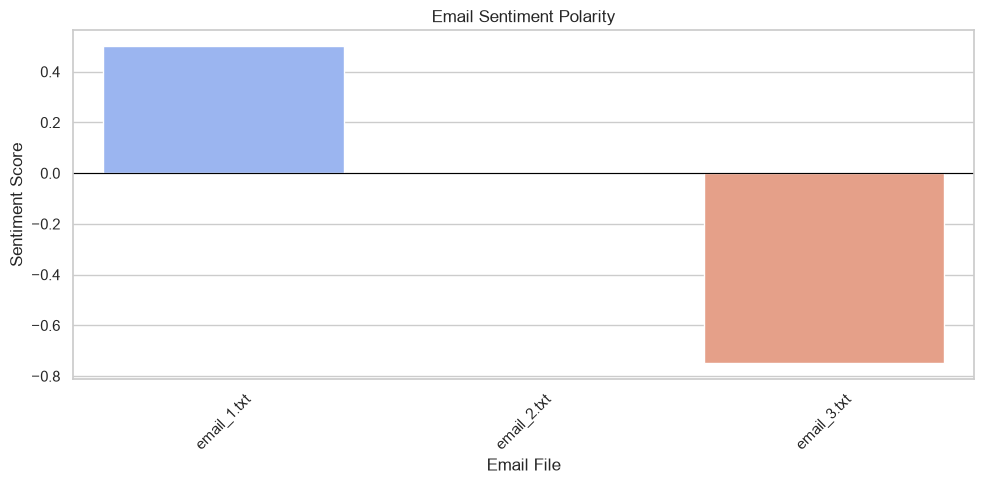

In [8]:
# Import Libraries
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert sentiment_results into a DataFrame
df = pd.DataFrame(sentiment_results, columns=["filename", "polarity"])

# Set Seaborn theme
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))

# Create barplot
sns.barplot(
    data=df,
    x="filename",
    y="polarity",
    palette="coolwarm",   # nice gradient from negative → positive
    dodge=False
)

# Add horizontal neutral line
plt.axhline(0, color="black", linewidth=0.8)

# Labels
plt.title("Email Sentiment Polarity")
plt.xlabel("Email File")
plt.ylabel("Sentiment Score")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
# Imports + Settings + IMAP Toggle
from wordcloud import WordCloud

# Toggle IMAP ingestion
USE_IMAP = False  # change to True if you want to pull real emails

email_texts = []

In [12]:
# Email Ingestion (IMAP or Local .txt)
# ---------------------------------------------------------
# 1. OPTIONAL: IMAP EMAIL INGESTION
# ---------------------------------------------------------
if USE_IMAP:
    from imapclient import IMAPClient
    import pyzmail

    HOST = "imap.gmail.com"
    USERNAME = "your_email@gmail.com"
    PASSWORD = "your_app_password"  # Gmail requires app password

    with IMAPClient(HOST) as client:
        client.login(USERNAME, PASSWORD)
        client.select_folder("INBOX")

        messages = client.search(["ALL"])

        for msgid, data in client.fetch(messages, ["RFC822"]).items():
            message = pyzmail.PyzMessage.factory(data[b"RFC822"])
            body = message.text_part.get_payload().decode(message.text_part.charset)
            email_texts.append(body)

# ---------------------------------------------------------
# 2. LOCAL EMAIL INGESTION (emails/*.txt)
# ---------------------------------------------------------
EMAIL_FOLDER = "emails"
sentiment_results = []

if not USE_IMAP:
    for filename in os.listdir(EMAIL_FOLDER):
        if filename.endswith(".txt"):
            file_path = os.path.join(EMAIL_FOLDER, filename)

            with open(file_path, "r", encoding="utf-8") as f:
                text = f.read()

            sentiment_results.append((filename, text))
else:
    sentiment_results = [(f"email_{i+1}", text) for i, text in enumerate(email_texts)]

In [13]:
# Sentiment Analysis + Category + DataFrame
def categorize(p):
    if p > 0:
        return "Positive"
    elif p < 0:
        return "Negative"
    else:
        return "Neutral"

rows = []
for filename, text in sentiment_results:
    blob = TextBlob(text)
    polarity = blob.sentiment.polarity
    category = categorize(polarity)
    rows.append([filename, text, polarity, category])

df = pd.DataFrame(rows, columns=["filename", "text", "polarity", "category"])

df

,filename,text,polarity,category
0,email_1.txt,"Hi team, great job on the recent project! The ...",0.50,Positive
1,email_2.txt,"Hello, please find the attached report for you...",0.00,Neutral
2,email_3.txt,I’m disappointed with the delays and the lack ...,-0.75,Negative


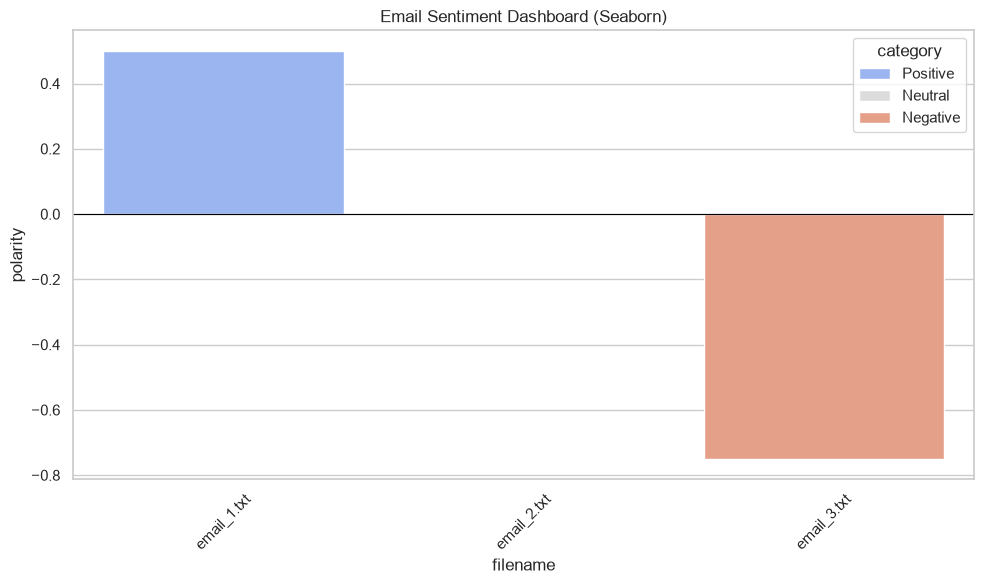

,filename,text,polarity,category
0,email_1.txt,"Hi team, great job on the recent project! The results were fantastic and I’m really proud of everyone.",0.500000,Positive
1,email_2.txt,"Hello, please find the attached report for your review. Let me know if you have any questions.",0.000000,Neutral
2,email_3.txt,I’m disappointed with the delays and the lack of communication. This needs to be improved immediately.,-0.750000,Negative


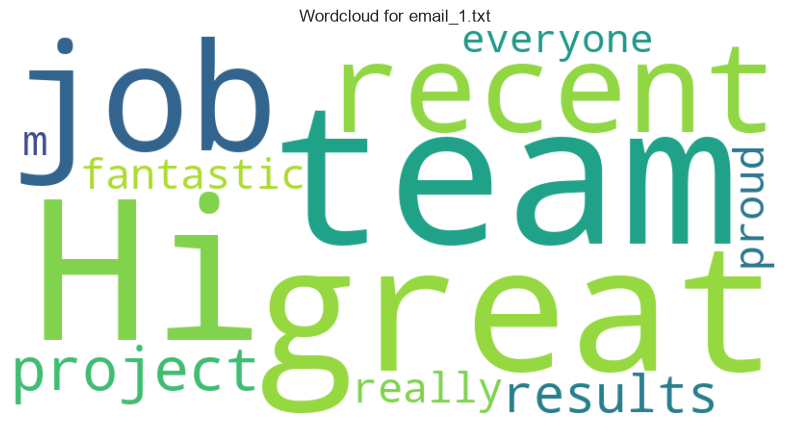

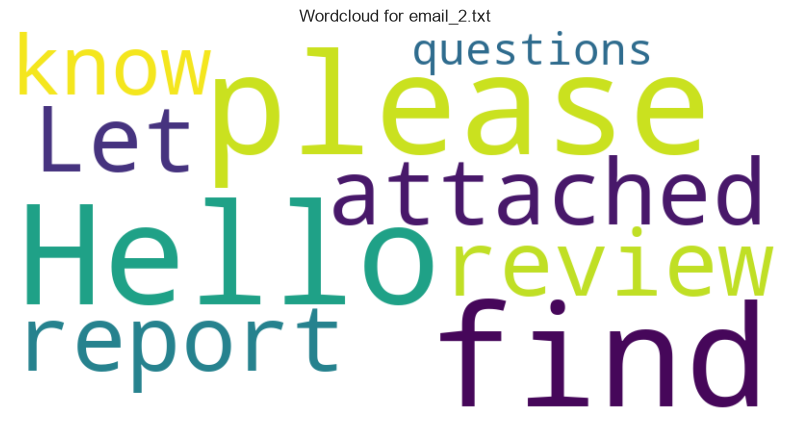

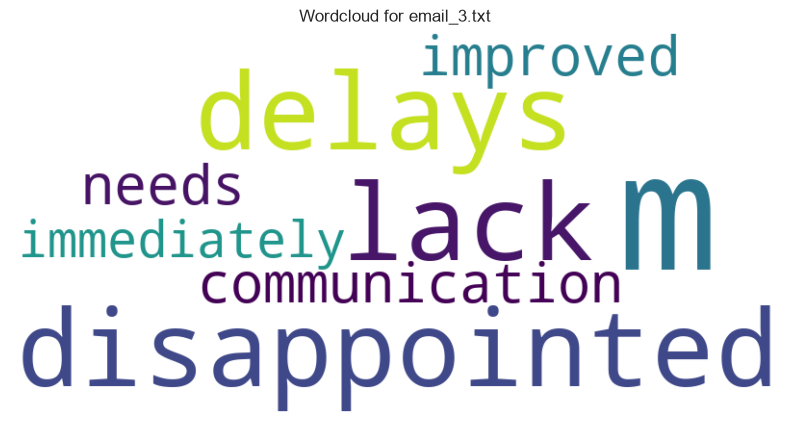

In [14]:
# Seaborn Dashboard + Table + Wordclouds
# ---------------------------------------------------------
# 4. SEABORN DASHBOARD
# ---------------------------------------------------------
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.barplot(
    data=df,
    x="filename",
    y="polarity",
    hue="category",
    palette="coolwarm",
    dodge=False
)

plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=45)
plt.title("Email Sentiment Dashboard (Seaborn)")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 5. TABLE DISPLAY
# ---------------------------------------------------------
display(df.style.background_gradient(cmap="coolwarm"))

# ---------------------------------------------------------
# 6. WORDCLOUD PER EMAIL
# ---------------------------------------------------------
for idx, row in df.iterrows():
    wc = WordCloud(width=800, height=400, background_color="white").generate(row["text"])

    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"Wordcloud for {row['filename']}")
    plt.show()